In [ ]:
# EXP8-9 T1 CELL 1 - Setup: libraries, global seed, Google Drive folders for splits, runs and figures.
!pip -q install tensorflow-datasets

import os, json, time, glob, random
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

SEED = 42
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)

from google.colab import drive
drive.mount("/content/drive")
ROOT    = "/content/drive/MyDrive/CS3807_Exp8_9"
FIG_DIR = f"{ROOT}/figures"
RUN_DIR = f"{ROOT}/runs"
for d in (ROOT, FIG_DIR, RUN_DIR):
    os.makedirs(d, exist_ok=True)

print("TF", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Mounted at /content/drive
TF 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# EXP8-9 T1 CELL 2 - Times New Roman figure style and save_fig (EPS, PDF, PNG). Falls back to Liberation Serif
# (metric-compatible with Times New Roman) when the MS core fonts cannot be downloaded.
!echo ttf-mscorefonts-installer msttcorefonts/accepted-mscorefonts-eula select true | sudo debconf-set-selections
!sudo apt-get -qq install -y ttf-mscorefonts-installer fonts-liberation > /dev/null 2>&1

for f in glob.glob("/usr/share/fonts/**/*.ttf", recursive=True):
    if any(k in f.lower() for k in ("times", "liberationserif")):
        fm.fontManager.addfont(f)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",          # math text also Times-like
    "axes.unicode_minus": False,
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "ps.fonttype": 42, "pdf.fonttype": 42,   # embed TrueType so text stays editable / correct in EPS and PDF
    "savefig.dpi": 300, "figure.dpi": 110,
})
print("Resolved font:", fm.findfont("serif"))

def save_fig(name):
    """Save the current figure as EPS, PDF and PNG into FIG_DIR."""
    for ext in ("eps", "pdf", "png"):
        plt.savefig(f"{FIG_DIR}/{name}.{ext}", bbox_inches="tight", dpi=300)
    print(f"saved: {name}.[eps|pdf|png]")

Resolved font: /usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf


In [ ]:
# EXP8-9 T1 CELL 3 - Download TF Flowers (same 3670 images as tfds 'tf_flowers'), extract manually, resize to 224x224,
# and create ONE stratified 70/15/15 split saved to Drive. Reused by every later experiment.
import tarfile, urllib.request

IMG = 224
NUM_CLASSES = 5
CACHE = f"{ROOT}/flowers_224.npz"
SPLIT = f"{ROOT}/split_seed{SEED}.npz"

URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
TGZ = "/content/flower_photos.tgz"
EXTRACT_DIR = "/content/flowers_raw"
data_dir = f"{EXTRACT_DIR}/flower_photos"

if not os.path.isdir(data_dir):
    if not os.path.exists(TGZ):
        print("Downloading ...")
        urllib.request.urlretrieve(URL, TGZ)
    print("Extracting ...")
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    with tarfile.open(TGZ, "r:gz") as tf_:
        tf_.extractall(EXTRACT_DIR)
assert os.path.isdir(data_dir), f"Not found: {data_dir} | contents: {os.listdir(EXTRACT_DIR)}"

CLASS_NAMES = sorted(d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d)))
print("Classes:", CLASS_NAMES)
assert len(CLASS_NAMES) == NUM_CLASSES

if os.path.exists(CACHE):
    z = np.load(CACHE); X, Y = z["X"], z["Y"]
else:
    xs, ys = [], []
    for c, cname in enumerate(CLASS_NAMES):
        files = sorted(glob.glob(os.path.join(data_dir, cname, "*.jpg")))     # sorted -> deterministic order
        for f in files:
            img = keras.utils.load_img(f, target_size=(IMG, IMG), color_mode="rgb")
            xs.append(np.asarray(img, dtype=np.uint8)); ys.append(c)
        print(f"  {cname}: {len(files)} images")
    X, Y = np.stack(xs), np.array(ys, dtype=np.int64)
    np.savez(CACHE, X=X, Y=Y)
print("X:", X.shape, X.dtype, "| Y:", Y.shape)

if os.path.exists(SPLIT):
    s = np.load(SPLIT); tr_idx, va_idx, te_idx = s["train"], s["val"], s["test"]
else:
    idx = np.arange(len(Y))
    tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=Y, random_state=SEED)
    va_idx, te_idx  = train_test_split(tmp_idx, test_size=0.50, stratify=Y[tmp_idx], random_state=SEED)
    np.savez(SPLIT, train=tr_idx, val=va_idx, test=te_idx)

x_train, y_train = X[tr_idx], Y[tr_idx]
x_val,   y_val   = X[va_idx], Y[va_idx]
x_test,  y_test  = X[te_idx], Y[te_idx]
print(f"Train {len(tr_idx)} | Val {len(va_idx)} | Test {len(te_idx)}")
for nm, yy in (("train", y_train), ("val", y_val), ("test", y_test)):
    print(nm, np.bincount(yy, minlength=NUM_CLASSES))

Extracting ...


/tmp/ipykernel_445/230324091.py:22: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf_.extractall(EXTRACT_DIR)


Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
X: (3670, 224, 224, 3) uint8 | Y: (3670,)
Train 2569 | Val 550 | Test 551
train [443 629 449 489 559]
val [ 95 134  96 105 120]
test [ 95 135  96 105 120]


In [ ]:
# EXP8-9 T1 CELL 4 - Input pipeline. Augmentation is applied to the TRAIN set only, then ResNet50 ImageNet preprocessing.
# The identical pipeline is reused for every model.
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE
preprocess = keras.applications.resnet50.preprocess_input

augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal", seed=SEED),
    keras.layers.RandomRotation(0.05, seed=SEED),          # about +/-18 degrees
    keras.layers.RandomZoom(0.10, seed=SEED),
    keras.layers.RandomTranslation(0.10, 0.10, seed=SEED),
    keras.layers.RandomContrast(0.10, seed=SEED),
], name="augment")

def make_ds(x, y, train):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if train:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH)
    def _prep(xb, yb):
        xb = tf.cast(xb, tf.float32)
        if train:
            xb = augment(xb, training=True)
        xb = preprocess(xb)                                   # RGB -> BGR, ImageNet mean subtraction
        return xb, tf.one_hot(yb, NUM_CLASSES)
    return ds.map(_prep, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

train_ds = make_ds(x_train, y_train, True)
val_ds   = make_ds(x_val,   y_val,   False)
test_ds  = make_ds(x_test,  y_test,  False)
xb, yb = next(iter(train_ds)); print("batch:", xb.shape, yb.shape)


batch: (32, 224, 224, 3) (32, 5)


saved: plot1_sample_images.[eps|pdf|png]


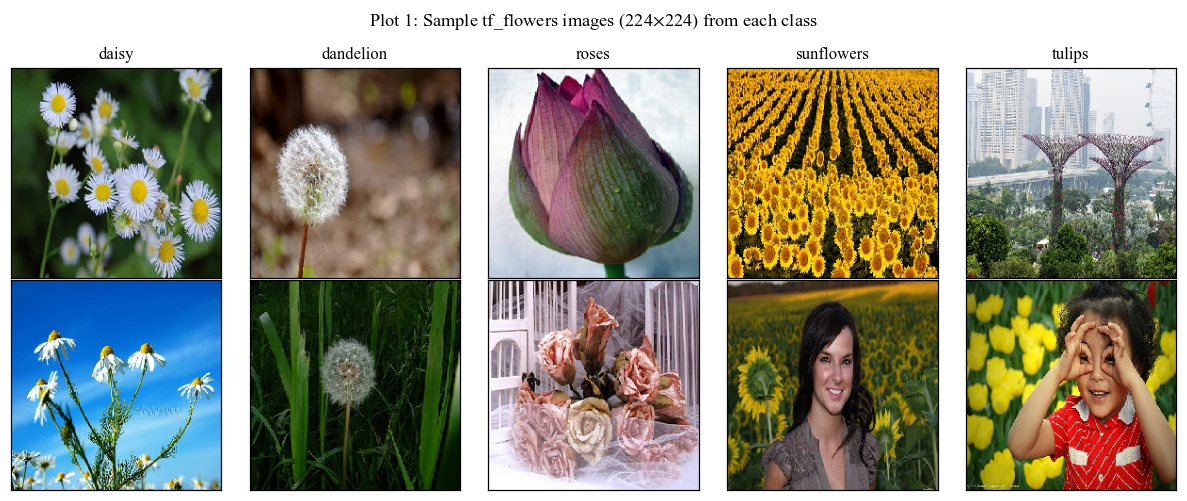

In [ ]:
# EXP8-9 T1 CELL 5 - PLOT 1: one sample image per class (required figure 1). Saved as EPS, PDF and PNG.
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(2.2 * NUM_CLASSES, 4.6))
rng = np.random.RandomState(SEED)
for c in range(NUM_CLASSES):
    cls_idx = np.where(y_train == c)[0]
    for r in range(2):
        j = rng.choice(cls_idx)
        axes[r, c].imshow(x_train[j]); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[0, c].set_title(CLASS_NAMES[c])
plt.suptitle("Plot 1: Sample tf_flowers images (224$\\times$224) from each class")
plt.tight_layout(); save_fig("plot1_sample_images"); plt.show()

In [ ]:
# EXP8-9 T1 CELL 6 - build_model(): ResNet50 is split into 5 stage sub-models that SHARE the pretrained weights:
# stem+conv2_x | conv3_x | conv4_x | conv5_x. An attention layer can be inserted after conv2_x (P1), conv3_x (P2),
# conv4_x (P3) or conv5_x (P4). attention = {} gives the baseline.  Usage: attention={"P3": lambda C: MyAttn(C)}
# Output shapes before/after every attention block are recorded and asserted equal.
STAGE_END = ["conv2_block3_out", "conv3_block4_out", "conv4_block6_out", "conv5_block3_out"]
POS_NAMES = ["P1", "P2", "P3", "P4"]

def build_model(attention=None, name="baseline", dropout=0.3):
    attention = attention or {}
    base = keras.applications.ResNet50(weights="imagenet", include_top=False, input_shape=(IMG, IMG, 3))
    base.trainable = False

    # stage sub-models (weight-sharing views on the pretrained graph)
    stages = [keras.Model(base.input, base.get_layer(STAGE_END[0]).output, name="stage_stem_conv2")]
    for k in range(1, 4):
        stages.append(keras.Model(base.get_layer(STAGE_END[k - 1]).output,
                                  base.get_layer(STAGE_END[k]).output, name=f"stage_conv{k + 2}"))

    inp = keras.Input((IMG, IMG, 3))
    x = inp
    shapes = {}
    for k, pos in enumerate(POS_NAMES):
        x = stages[k](x, training=False)               # BatchNorm kept in inference mode in every stage
        if pos in attention:
            before = tuple(x.shape[1:])
            x = attention[pos](x.shape[-1])(x)         # factory(channels) -> layer
            after = tuple(x.shape[1:])
            assert before == after, f"{pos}: attention changed shape {before} -> {after}"
            shapes[pos] = {"before": before, "after": after}
    x = keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = keras.layers.Dropout(dropout, name="dropout")(x)
    out = keras.layers.Dense(NUM_CLASSES, activation="softmax", name="classifier")(x)
    model = keras.Model(inp, out, name=name)
    return model, base, shapes

def unfreeze_last_stage(base):
    """Unfreeze conv5_x only; BatchNorm layers stay frozen (standard fine-tuning practice)."""
    for l in base.layers:
        if l.name.startswith("conv5_") and not isinstance(l, keras.layers.BatchNormalization):
            l.trainable = True

# quick sanity check on the baseline
m, b, sh = build_model(name="check")
m.summary(line_length=100, expand_nested=False)
print("Stage output shapes:")
for pos, nm in zip(POS_NAMES, STAGE_END):
    print(f"  {pos} after {nm}: {b.get_layer(nm).output.shape[1:]}")
del m, b

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "check"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)                 │ (None, 224, 224, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ stage_stem_conv2 (Functional)              │ (None, 56, 56, 256)             │           229,760 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ stage_conv3 (Functional)                   │ (None, 28, 28, 512)             │         1,230,336 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ stage_conv4 (Functional)                   │ (None, 14, 14, 1024)            │         7,129,088 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ stage_conv5 (Functional)                   │ (None, 7, 7, 2048)              │        14,998,528 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ gap (GlobalAveragePooling2D)               │ (None, 2048)                    │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ dropout (Dropout)                          │ (None, 2048)                    │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ classifier (Dense)                         │ (None, 5)                       │            10,245 │
└────────────────────────────────────────────┴─────────────────────────────────┴───────────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Stage output shapes:
  P1 after conv2_block3_out: (56, 56, 256)
  P2 after conv3_block4_out: (28, 28, 512)
  P3 after conv4_block6_out: (14, 14, 1024)
  P4 after conv5_block3_out: (7, 7, 2048)


In [ ]:
# TUNE CELL 1 - Hyperparameter search on the BASELINE ResNet50 (no attention). All scoring is on the VALIDATION set.
# Trial T00 is the original protocol; its already trained weights are reused (no retraining). The other trials are a seeded
# random sample of the grid below, so the same trials are generated in every session.
import itertools, gc
import pandas as pd
from sklearn.metrics import f1_score

TUNE_DIR = f"{ROOT}/tuning"; os.makedirs(TUNE_DIR, exist_ok=True)
DEFAULT_CFG = {"lr_head": 1e-3, "lr_ft": 1e-4, "dropout": 0.3, "unfreeze": "conv5", "ft_sched": "const",
               "epochs_head": 5, "epochs_ft": 5}
SPACE = {
    "lr_head":  [1e-3, 5e-4, 3e-4],            # learning rate while the backbone is frozen
    "lr_ft":    [1e-5, 3e-5, 1e-4],            # fine-tuning learning rate
    "dropout":  [0.2, 0.3, 0.5],
    "unfreeze": ["conv5", "conv4+conv5"],      # how much of the backbone is fine-tuned
    "ft_sched": ["const", "cosine"],           # fine-tuning learning-rate schedule
}
N_RANDOM = 5                                    # extra trials besides the default (each takes about 15 minutes)

grid = list(itertools.product(*SPACE.values()))
default_vals = tuple(DEFAULT_CFG[k] for k in SPACE)
def cfg_from(vals):
    d = dict(DEFAULT_CFG); d.update(dict(zip(SPACE, vals))); return d

order = [g for g in (grid[i] for i in np.random.RandomState(SEED).permutation(len(grid))) if g != default_vals]
TRIALS = [("T00_default", cfg_from(default_vals))] + [(f"T{i:02d}", cfg_from(g)) for i, g in enumerate(order[:N_RANDOM], 1)]
print(f"{len(grid)} possible configurations, {len(TRIALS)} trials selected")
for n, c in TRIALS:
    print(f"  {n:12s} { {k: c[k] for k in SPACE} }")

def set_trainable(base, which):
    """Unfreeze the chosen stages; BatchNorm layers stay frozen (standard fine-tuning practice)."""
    prefixes = {"conv5": ("conv5_",), "conv4+conv5": ("conv4_", "conv5_")}[which]
    for l in base.layers:
        if l.name.startswith(prefixes) and not isinstance(l, keras.layers.BatchNormalization):
            l.trainable = True

def train_cfg(model, base, cfg, ckpt, verbose=2):
    """Same two-stage procedure as the main protocol, with configurable hyperparameters."""
    steps = int(tf.data.experimental.cardinality(train_ds).numpy())
    model.compile(keras.optimizers.Adam(cfg["lr_head"]), loss="categorical_crossentropy", metrics=["accuracy"])
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=cfg["epochs_head"], verbose=verbose)
    set_trainable(base, cfg["unfreeze"])
    lr = cfg["lr_ft"]
    if cfg["ft_sched"] == "cosine":
        lr = keras.optimizers.schedules.CosineDecay(cfg["lr_ft"], decay_steps=cfg["epochs_ft"] * steps, alpha=0.1)
    model.compile(keras.optimizers.Adam(lr), loss="categorical_crossentropy", metrics=["accuracy"])
    cb = keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, save_weights_only=True)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=cfg["epochs_ft"], callbacks=[cb], verbose=verbose)
    model.load_weights(ckpt)
    return {k: [float(v) for v in h1.history[k] + h2.history[k]] for k in h1.history}

108 possible configurations, 6 trials selected
  T00_default  {'lr_head': 0.001, 'lr_ft': 0.0001, 'dropout': 0.3, 'unfreeze': 'conv5', 'ft_sched': 'const'}
  T01          {'lr_head': 0.0003, 'lr_ft': 1e-05, 'dropout': 0.3, 'unfreeze': 'conv5', 'ft_sched': 'cosine'}
  T02          {'lr_head': 0.001, 'lr_ft': 1e-05, 'dropout': 0.5, 'unfreeze': 'conv4+conv5', 'ft_sched': 'const'}
  T03          {'lr_head': 0.001, 'lr_ft': 1e-05, 'dropout': 0.3, 'unfreeze': 'conv5', 'ft_sched': 'const'}
  T04          {'lr_head': 0.0003, 'lr_ft': 1e-05, 'dropout': 0.5, 'unfreeze': 'conv4+conv5', 'ft_sched': 'cosine'}
  T05          {'lr_head': 0.0005, 'lr_ft': 0.0001, 'dropout': 0.2, 'unfreeze': 'conv4+conv5', 'ft_sched': 'const'}


In [ ]:
# TUNE CELL 2 - Train each configuration on the training split and score it on the validation split (test set untouched).
# Each finished trial is saved to Drive, so after a disconnect this cell continues with the next unfinished trial.
def val_scores(model):
    probs = np.concatenate([model(xb, training=False).numpy() for xb, _ in val_ds])      # val_ds is not shuffled
    yp = probs.argmax(1)
    return (float(accuracy_score(y_val, yp)), float(f1_score(y_val, yp, average="macro")),
            float(-np.mean(np.log(probs[np.arange(len(y_val)), y_val] + 1e-12))))

def run_trial(name, cfg):
    path = f"{TUNE_DIR}/trial_{name}.json"
    if os.path.exists(path):
        print(f"[{name}] found saved result, skipping"); return json.load(open(path))
    keras.backend.clear_session(); gc.collect()
    t0 = time.time()
    a0_w, a0_h = f"{RUN_DIR}/A0_baseline_best.weights.h5", f"{RUN_DIR}/A0_baseline_history.json"
    if name == "T00_default" and os.path.exists(a0_w) and os.path.exists(a0_h):
        print("[T00_default] reusing the already trained baseline (original protocol)")
        model, base, _ = build_model(attention={}, name="tune_T00", dropout=cfg["dropout"])
        model.load_weights(a0_w); hist = json.load(open(a0_h))
    else:
        keras.utils.set_random_seed(SEED)
        print(f"\n=== {name}: { {k: cfg[k] for k in SPACE} }")
        model, base, _ = build_model(attention={}, name=f"tune_{name}", dropout=cfg["dropout"])
        hist = train_cfg(model, base, cfg, f"{TUNE_DIR}/{name}_best.weights.h5")
    va, vf, vl = val_scores(model)
    eh = cfg["epochs_head"]; b = eh + int(np.argmin(hist["val_loss"][eh:]))
    rec = dict(name=name, cfg=cfg, val_acc=va, val_f1=vf, val_loss=vl, train_acc=float(hist["accuracy"][b]),
               best_epoch=b + 1, minutes=round((time.time() - t0) / 60, 1),
               val_loss_curve=hist["val_loss"], val_acc_curve=hist["val_accuracy"], phase_boundary=eh)
    json.dump(rec, open(path, "w"), indent=2)
    print(f"[{name}] val acc {va:.4f} | val macro-F1 {vf:.4f} | val loss {vl:.4f} | {rec['minutes']} min")
    del model, base; gc.collect()
    return rec

TRIAL_RES = {name: run_trial(name, cfg) for name, cfg in TRIALS}

[T00_default] found saved result, skipping
[T01] found saved result, skipping

=== T02: {'lr_head': 0.001, 'lr_ft': 1e-05, 'dropout': 0.5, 'unfreeze': 'conv4+conv5', 'ft_sched': 'const'}
Epoch 1/5
81/81 - 69s - 849ms/step - accuracy: 0.6146 - loss: 1.0729 - val_accuracy: 0.8545 - val_loss: 0.4267
Epoch 2/5
81/81 - 60s - 741ms/step - accuracy: 0.8054 - loss: 0.5486 - val_accuracy: 0.8873 - val_loss: 0.3360
Epoch 3/5
81/81 - 41s - 503ms/step - accuracy: 0.8435 - loss: 0.4298 - val_accuracy: 0.8945 - val_loss: 0.3179
Epoch 4/5
81/81 - 40s - 492ms/step - accuracy: 0.8599 - loss: 0.3902 - val_accuracy: 0.8909 - val_loss: 0.3106
Epoch 5/5
81/81 - 42s - 518ms/step - accuracy: 0.8606 - loss: 0.3704 - val_accuracy: 0.8800 - val_loss: 0.3363
Epoch 1/5
81/81 - 90s - 1s/step - accuracy: 0.8902 - loss: 0.3101 - val_accuracy: 0.9127 - val_loss: 0.2426
Epoch 2/5
81/81 - 51s - 629ms/step - accuracy: 0.9221 - loss: 0.2166 - val_accuracy: 0.9164 - val_loss: 0.2304
Epoch 3/5
81/81 - 49s - 608ms/step - ac

,Trial,lr_head,lr_ft,dropout,unfreeze,ft_sched,Val acc,Val macro F1,Val loss,Train acc,Train-Val gap,Best FT epoch
0,T05,0.000500,0.000100,0.200000,conv4+conv5,const,0.9327,0.9311,0.2126,0.9587,0.0260,10
1,T02,0.001000,0.000010,0.500000,conv4+conv5,const,0.9291,0.9283,0.2302,0.9560,0.0269,10
2,T00_default,0.001000,0.000100,0.300000,conv5,const,0.9273,0.9258,0.2163,0.9689,0.0416,15
3,T03,0.001000,0.000010,0.300000,conv5,const,0.9200,0.9190,0.2696,0.9521,0.0321,9
4,T01,0.000300,0.000010,0.300000,conv5,cosine,0.9200,0.9188,0.2593,0.9463,0.0263,13
5,T04,0.000300,0.000010,0.500000,conv4+conv5,cosine,0.9127,0.9118,0.2581,0.9280,0.0153,9



Spread of validation macro-F1 across trials: 0.9118 to 0.9311
One standard error of accuracy on 550 validation images is about 1.1%.
saved: plot_tuning_ranking.[eps|pdf|png]


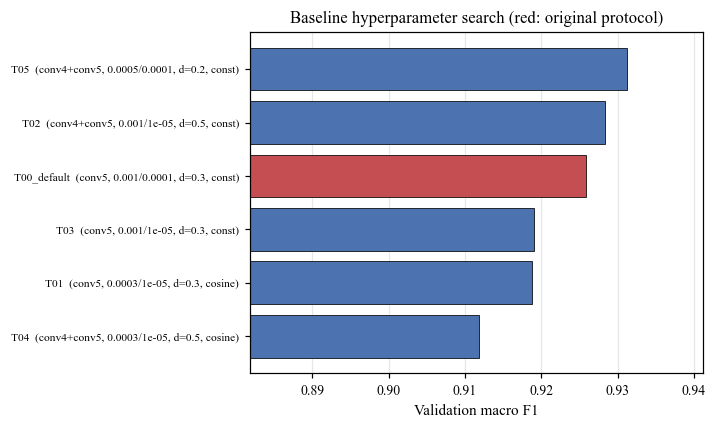

saved: plot_tuning_val_curves.[eps|pdf|png]


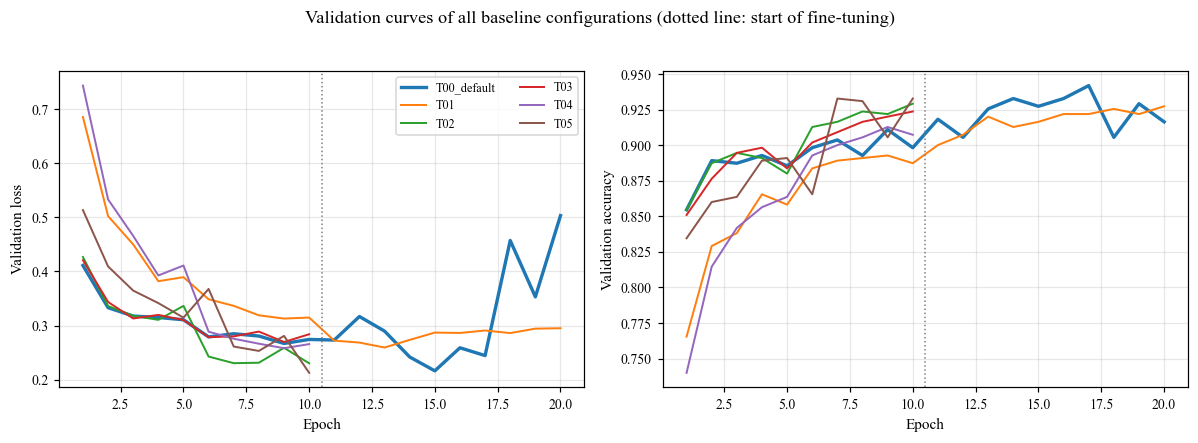

In [ ]:
# TUNE CELL 3 - Hyperparameter-search results (validation set): table (CSV + LaTeX), ranking plot, validation curves of all trials.
rows = []
for name, cfg in TRIALS:
    r = TRIAL_RES[name]
    rows.append({"Trial": name, **{k: cfg[k] for k in SPACE},
                 "Val acc": r["val_acc"], "Val macro F1": r["val_f1"], "Val loss": r["val_loss"],
                 "Train acc": r["train_acc"], "Train-Val gap": r["train_acc"] - r["val_acc"], "Best FT epoch": r["best_epoch"]})
df_tune = pd.DataFrame(rows).sort_values(["Val macro F1", "Val loss"], ascending=[False, True]).reset_index(drop=True)
display(df_tune.style.format({c: "{:.4f}" for c in ["Val acc", "Val macro F1", "Val loss", "Train acc", "Train-Val gap"]}))
df_tune.to_csv(f"{TUNE_DIR}/table_tuning.csv", index=False)
df_tune.to_latex(f"{TUNE_DIR}/table_tuning.tex", index=False, float_format="%.4f")

se = np.sqrt(0.93 * 0.07 / len(y_val))
print(f"\nSpread of validation macro-F1 across trials: {df_tune['Val macro F1'].min():.4f} to {df_tune['Val macro F1'].max():.4f}")
print(f"One standard error of accuracy on {len(y_val)} validation images is about {se * 100:.1f}%.")

# PLOT A: ranking of the trials
fig, ax = plt.subplots(figsize=(6.6, 0.45 * len(df_tune) + 1.3))
cols = ["#C44E52" if t == "T00_default" else "#4C72B0" for t in df_tune["Trial"]]
ax.barh(range(len(df_tune))[::-1], df_tune["Val macro F1"], color=cols, edgecolor="black", linewidth=0.5)
ax.set_yticks(range(len(df_tune))[::-1])
ax.set_yticklabels([f"{t}  ({u}, {a:g}/{b:g}, d={d}, {s})" for t, u, a, b, d, s in
                    zip(df_tune["Trial"], df_tune["unfreeze"], df_tune["lr_head"], df_tune["lr_ft"], df_tune["dropout"], df_tune["ft_sched"])], fontsize=7.5)
ax.set_xlim(max(0, df_tune["Val macro F1"].min() - 0.03), min(1, df_tune["Val macro F1"].max() + 0.01))
ax.set_xlabel("Validation macro F1"); ax.set_title("Baseline hyperparameter search (red: original protocol)")
ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
plt.tight_layout(); save_fig("plot_tuning_ranking"); plt.show()

# PLOT B: validation loss and accuracy curves of every trial
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
colors = plt.cm.tab10(np.linspace(0, 1, 10))
for i, (name, _) in enumerate(TRIALS):
    r = TRIAL_RES[name]; ep = np.arange(1, len(r["val_loss_curve"]) + 1)
    lw = 2.2 if name == "T00_default" else 1.3
    axes[0].plot(ep, r["val_loss_curve"], color=colors[i], lw=lw, label=name)
    axes[1].plot(ep, r["val_acc_curve"], color=colors[i], lw=lw, label=name)
for ax, yl in zip(axes, ["Validation loss", "Validation accuracy"]):
    ax.axvline(TRIAL_RES["T00_default"]["phase_boundary"] + 0.5, ls=":", c="gray", lw=1)
    ax.set_xlabel("Epoch"); ax.set_ylabel(yl); ax.grid(alpha=0.3)
axes[0].legend(ncol=2, fontsize=8)
plt.suptitle("Validation curves of all baseline configurations (dotted line: start of fine-tuning)", y=1.02)
plt.tight_layout(); save_fig("plot_tuning_val_curves"); plt.show()

In [ ]:
# EXP8-9 T1 CELL 7 - Identical transfer-learning protocol for ALL models:
# Stage 1: backbone frozen, train attention+head (Adam, lr 1e-3).  Stage 2: unfreeze conv5_x, fine-tune (Adam, lr 1e-4).
# Best weights (lowest val loss) of the fine-tuning stage are restored before testing.
EPOCHS_HEAD, EPOCHS_FT = 10, 10
LR_HEAD, LR_FT = 1e-3, 1e-4

def merge_hist(h1, h2):
    return {k: [float(v) for v in h1.history[k] + h2.history[k]] for k in h1.history}

def train_model(model, base, tag):
    ckpt = f"{RUN_DIR}/{tag}_best.weights.h5"
    model.compile(keras.optimizers.Adam(LR_HEAD), loss="categorical_crossentropy", metrics=["accuracy"])
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, verbose=2)

    unfreeze_last_stage(base)
    model.compile(keras.optimizers.Adam(LR_FT), loss="categorical_crossentropy", metrics=["accuracy"])   # recompile after unfreezing
    cb = keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, save_weights_only=True)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, callbacks=[cb], verbose=2)
    model.load_weights(ckpt)

    hist = merge_hist(h1, h2); hist["phase_boundary"] = EPOCHS_HEAD
    json.dump(hist, open(f"{RUN_DIR}/{tag}_history.json", "w"))
    return hist

In [ ]:
# EXP8-9 T1 CELL 8 - evaluate(): accuracy, macro P/R/F1, trainable/total params, inference time per image, confusion matrix.
# Results are stored in RUN_DIR as JSON + NPY so tables and plots can be rebuilt later without retraining.
def evaluate(model, tag, shapes=None):
    batches = [(xb, yb) for xb, yb in test_ds]                    # cached once: timing excludes the data pipeline
    probs = np.concatenate([model(xb, training=False).numpy() for xb, _ in batches])
    y_pred = probs.argmax(1)

    acc = accuracy_score(y_test, y_pred)
    P, R, F1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASSES))

    for xb, _ in batches[:3]:                                     # GPU warm-up
        model(xb, training=False).numpy()
    times = []
    for _ in range(3):
        t0 = time.perf_counter()
        for xb, _ in batches:
            model(xb, training=False).numpy()                     # .numpy() forces GPU sync
        times.append((time.perf_counter() - t0) / len(y_test))
    ms_per_img = 1000 * float(np.median(times))

    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    res = dict(tag=tag, accuracy=float(acc), precision=float(P), recall=float(R), f1=float(F1),
               trainable_params=trainable, total_params=int(model.count_params()),
               inference_ms_per_image=ms_per_img, attention_shapes=shapes or {})
    json.dump(res, open(f"{RUN_DIR}/{tag}_results.json", "w"), indent=2)
    np.save(f"{RUN_DIR}/{tag}_cm.npy", cm); np.save(f"{RUN_DIR}/{tag}_probs.npy", probs)

    print(f"[{tag}] Acc {acc:.4f} | P {P:.4f} | R {R:.4f} | F1 {F1:.4f} | "
          f"trainable {trainable:,} | total {res['total_params']:,} | {ms_per_img:.3f} ms/img")
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
    return res

In [ ]:
# EXP8-9 T1 CELL 9 - Experiment A0: baseline pretrained ResNet50 (no attention). Reference for all later comparisons.
keras.utils.set_random_seed(SEED)
model_A0, base_A0, shapes_A0 = build_model(attention={}, name="A0_baseline")
hist_A0 = train_model(model_A0, base_A0, "A0_baseline")
res_A0  = evaluate(model_A0, "A0_baseline", shapes_A0)

Epoch 1/10
81/81 - 77s - 954ms/step - accuracy: 0.6719 - loss: 0.8909 - val_accuracy: 0.8545 - val_loss: 0.4065
Epoch 2/10
81/81 - 43s - 530ms/step - accuracy: 0.8412 - loss: 0.4371 - val_accuracy: 0.8836 - val_loss: 0.3299
Epoch 3/10
81/81 - 42s - 513ms/step - accuracy: 0.8739 - loss: 0.3534 - val_accuracy: 0.9000 - val_loss: 0.3172
Epoch 4/10
81/81 - 40s - 488ms/step - accuracy: 0.8976 - loss: 0.2908 - val_accuracy: 0.8982 - val_loss: 0.3002
Epoch 5/10
81/81 - 39s - 483ms/step - accuracy: 0.8953 - loss: 0.2860 - val_accuracy: 0.8927 - val_loss: 0.3316
Epoch 6/10
81/81 - 41s - 510ms/step - accuracy: 0.8961 - loss: 0.2759 - val_accuracy: 0.9036 - val_loss: 0.2729
Epoch 7/10
81/81 - 42s - 522ms/step - accuracy: 0.9050 - loss: 0.2621 - val_accuracy: 0.9018 - val_loss: 0.2868
Epoch 8/10
81/81 - 41s - 510ms/step - accuracy: 0.9105 - loss: 0.2379 - val_accuracy: 0.9055 - val_loss: 0.2835
Epoch 9/10
81/81 - 40s - 493ms/step - accuracy: 0.9245 - loss: 0.2087 - val_accuracy: 0.9055 - val_loss:

saved: plot2_A0_accuracy.[eps|pdf|png]


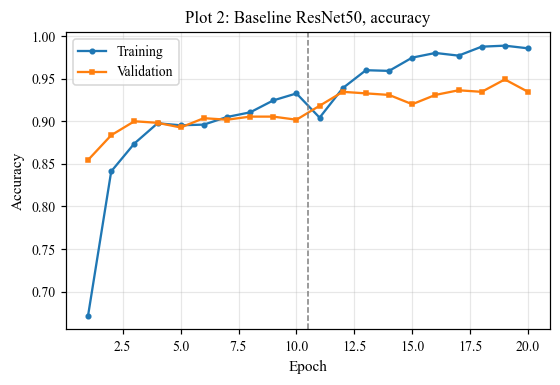

saved: plot3_A0_loss.[eps|pdf|png]


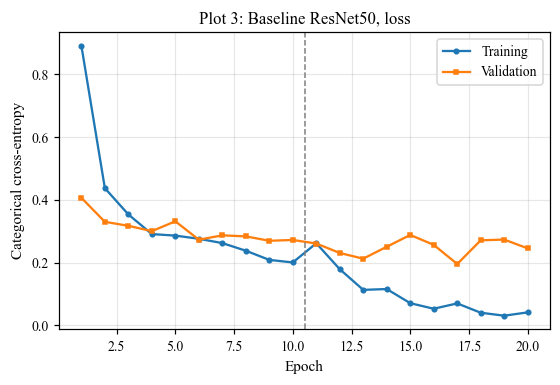

In [ ]:
# EXP8-9 T1 CELL 10 - PLOT 2 and PLOT 3: train/val accuracy and loss versus epoch (required figures 2 and 3).
# The dashed line marks the switch from head training to fine-tuning.
def plot_curves(hist, key, ylabel, title, fname):
    ep = np.arange(1, len(hist[key]) + 1)
    plt.figure(figsize=(5.2, 3.6))
    plt.plot(ep, hist[key], "-o", ms=3, label="Training")
    plt.plot(ep, hist["val_" + key], "-s", ms=3, label="Validation")
    plt.axvline(hist["phase_boundary"] + 0.5, ls="--", c="gray", lw=1)
    plt.xlabel("Epoch"); plt.ylabel(ylabel); plt.title(title)
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); save_fig(fname); plt.show()

plot_curves(hist_A0, "accuracy", "Accuracy", "Plot 2: Baseline ResNet50, accuracy", "plot2_A0_accuracy")
plot_curves(hist_A0, "loss", "Categorical cross-entropy", "Plot 3: Baseline ResNet50, loss", "plot3_A0_loss")

saved: plot4_A0_confusion.[eps|pdf|png]


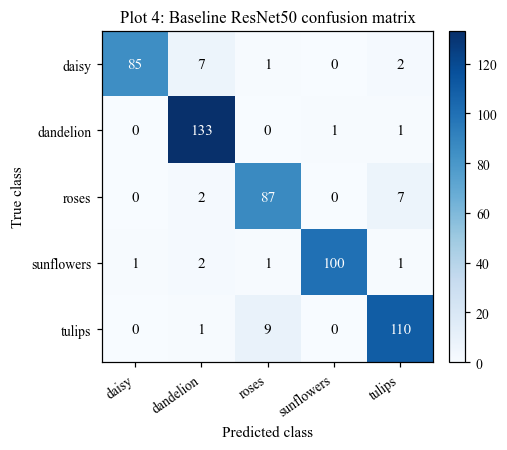

In [ ]:
# EXP8-9 T1 CELL 11 - PLOT 4: confusion matrix of the baseline on the test set (counts), saved as EPS, PDF and PNG.
def plot_cm(cm, title, fname):
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=35, ha="right"); ax.set_yticklabels(CLASS_NAMES)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title)
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.tight_layout(); save_fig(fname); plt.show()

plot_cm(np.load(f"{RUN_DIR}/A0_baseline_cm.npy"), "Plot 4: Baseline ResNet50 confusion matrix", "plot4_A0_confusion")

In [ ]:
# T2 CELL 1 - Attention modules as Keras layers. Every layer returns a tensor with the SAME shape as its input.
# Each module also exposes a method that returns its internal map (channel_weights / spatial_map / attn_matrix),
# which is used later for the attention visualizations.
import math
from tensorflow.keras import layers
ops = keras.ops

class ChannelAttention(layers.Layer):
    """GAP -> FC(C/r) -> ReLU -> FC(C) -> sigmoid -> channel re-scaling (reduction ratio r = 16)."""
    def __init__(self, channels, reduction=16, **kw):
        super().__init__(**kw)
        self.channels, self.reduction = channels, reduction
        self.fc1 = layers.Dense(max(channels // reduction, 1), activation="relu")
        self.fc2 = layers.Dense(channels, activation="sigmoid")
    def channel_weights(self, x):                      # (B, C)
        return self.fc2(self.fc1(ops.mean(x, axis=[1, 2])))
    def call(self, x):
        return x * ops.reshape(self.channel_weights(x), (-1, 1, 1, self.channels))

class SpatialAttention(layers.Layer):
    """Channel-wise mean and max -> concat -> Conv(k x k) -> sigmoid -> spatial re-scaling."""
    def __init__(self, kernel_size=7, **kw):
        super().__init__(**kw)
        self.conv = layers.Conv2D(1, kernel_size, padding="same", activation="sigmoid")
    def spatial_map(self, x):                          # (B, H, W, 1)
        s = ops.concatenate([ops.mean(x, axis=-1, keepdims=True),
                             ops.max(x, axis=-1, keepdims=True)], axis=-1)
        return self.conv(s)
    def call(self, x):
        return x * self.spatial_map(x)

class ChannelSpatialAttention(layers.Layer):
    """Sequential channel and spatial attention. order='cs' (channel first) or 'sc' (spatial first)."""
    def __init__(self, channels, order="cs", kernel_size=7, reduction=16, **kw):
        super().__init__(**kw)
        self.order = order
        self.ca = ChannelAttention(channels, reduction)
        self.sa = SpatialAttention(kernel_size)
    def call(self, x):
        if self.order == "cs":
            return self.sa(self.ca(x))
        return self.ca(self.sa(x))

class SelfAttention(layers.Layer):
    """Lightweight self-attention: Q, K from 1x1 convs (C/8), V from 1x1 conv (C), softmax(QK^T / sqrt(d)),
    residual output F + gamma * Y with a learnable gamma (initialised to 0 so the pretrained features start unchanged)."""
    def __init__(self, channels, key_ratio=8, **kw):
        super().__init__(**kw)
        self.channels, self.d = channels, max(channels // key_ratio, 1)
        self.q = layers.Conv2D(self.d, 1, use_bias=False)
        self.k = layers.Conv2D(self.d, 1, use_bias=False)
        self.v = layers.Conv2D(channels, 1, use_bias=False)
    def build(self, input_shape):
        self.h, self.w = int(input_shape[1]), int(input_shape[2])
        self.gamma = self.add_weight(name="gamma", shape=(), initializer="zeros", trainable=True)
    def attn_matrix(self, x):                          # (B, N, N) with N = H*W
        n = self.h * self.w
        q = ops.reshape(self.q(x), (-1, n, self.d))
        k = ops.reshape(self.k(x), (-1, n, self.d))
        return ops.softmax(ops.matmul(q, ops.transpose(k, (0, 2, 1))) / float(math.sqrt(self.d)), axis=-1)
    def call(self, x):
        n = self.h * self.w
        a = self.attn_matrix(x)
        v = ops.reshape(self.v(x), (-1, n, self.channels))
        y = ops.reshape(ops.matmul(a, v), (-1, self.h, self.w, self.channels))
        return x + self.gamma * y

class CombinedAttention(layers.Layer):
    """Channel -> Spatial -> Self-attention in sequence."""
    def __init__(self, channels, kernel_size=7, **kw):
        super().__init__(**kw)
        self.cs = ChannelSpatialAttention(channels, "cs", kernel_size)
        self.sa = SelfAttention(channels)
    def call(self, x):
        return self.sa(self.cs(x))

# ---------- additional established mechanisms ----------
class ECAAttention(layers.Layer):
    """Efficient Channel Attention: GAP -> 1-D conv across channels (adaptive kernel size) -> sigmoid."""
    def __init__(self, channels, gamma=2, b=1, **kw):
        super().__init__(**kw)
        self.channels = channels
        t = int(abs((math.log2(channels) + b) / gamma))
        self.ksize = t if t % 2 else t + 1
        self.conv = layers.Conv1D(1, self.ksize, padding="same", use_bias=False)
    def channel_weights(self, x):                      # (B, C)
        z = ops.expand_dims(ops.mean(x, axis=[1, 2]), -1)
        return ops.squeeze(ops.sigmoid(self.conv(z)), -1)
    def call(self, x):
        return x * ops.reshape(self.channel_weights(x), (-1, 1, 1, self.channels))

class CBAMChannel(layers.Layer):
    """CBAM channel branch: shared MLP applied to average-pooled and max-pooled descriptors, summed, sigmoid."""
    def __init__(self, channels, reduction=16, **kw):
        super().__init__(**kw)
        self.channels = channels
        self.fc1 = layers.Dense(max(channels // reduction, 1), activation="relu")
        self.fc2 = layers.Dense(channels)
    def channel_weights(self, x):
        avg = self.fc2(self.fc1(ops.mean(x, axis=[1, 2])))
        mx  = self.fc2(self.fc1(ops.max(x, axis=[1, 2])))
        return ops.sigmoid(avg + mx)
    def call(self, x):
        return x * ops.reshape(self.channel_weights(x), (-1, 1, 1, self.channels))

class CBAM(layers.Layer):
    """Convolutional Block Attention Module: CBAM channel branch followed by the 7x7 spatial branch."""
    def __init__(self, channels, kernel_size=7, reduction=16, **kw):
        super().__init__(**kw)
        self.ca = CBAMChannel(channels, reduction)
        self.sa = SpatialAttention(kernel_size)
    def call(self, x):
        return self.sa(self.ca(x))

class CoordAttention(layers.Layer):
    """Coordinate Attention: direction-aware pooling along H and W, shared 1x1 transform, two sigmoid gates."""
    def __init__(self, channels, reduction=32, **kw):
        super().__init__(**kw)
        mid = max(8, channels // reduction)
        self.conv1 = layers.Conv2D(mid, 1)
        self.bn = layers.BatchNormalization()
        self.conv_h = layers.Conv2D(channels, 1, activation="sigmoid")
        self.conv_w = layers.Conv2D(channels, 1, activation="sigmoid")
    def build(self, input_shape):
        self.h, self.w = int(input_shape[1]), int(input_shape[2])
    def call(self, x, training=None):
        xh = ops.mean(x, axis=2, keepdims=True)                                   # (B, H, 1, C)
        xw = ops.transpose(ops.mean(x, axis=1, keepdims=True), (0, 2, 1, 3))      # (B, W, 1, C)
        y = self.bn(self.conv1(ops.concatenate([xh, xw], axis=1)), training=training)
        y = y * ops.relu6(y + 3.0) / 6.0                                          # hard-swish
        ah = self.conv_h(y[:, :self.h])                                           # (B, H, 1, C)
        aw = ops.transpose(self.conv_w(y[:, self.h:]), (0, 2, 1, 3))              # (B, 1, W, C)
        return x * ah * aw

# registry: name -> factory(channels) used by build_model(attention={"P3": ATTENTION["channel"]})
ATTENTION = {
    "channel":         lambda C: ChannelAttention(C, name="channel_att"),
    "spatial":         lambda C: SpatialAttention(7, name="spatial_att"),
    "channel_spatial": lambda C: ChannelSpatialAttention(C, "cs", 7, name="channel_spatial_att"),
    "spatial_channel": lambda C: ChannelSpatialAttention(C, "sc", 7, name="spatial_channel_att"),
    "self":            lambda C: SelfAttention(C, name="self_att"),
    "combined":        lambda C: CombinedAttention(C, name="combined_att"),
    "eca":             lambda C: ECAAttention(C, name="eca_att"),
    "cbam":            lambda C: CBAM(C, name="cbam_att"),
    "coord":           lambda C: CoordAttention(C, name="coord_att"),
}
print("Registered:", list(ATTENTION))

Registered: ['channel', 'spatial', 'channel_spatial', 'spatial_channel', 'self', 'combined', 'eca', 'cbam', 'coord']


In [ ]:
# T2 CELL 2 - Unit test: every module must keep the feature shape unchanged at every ResNet50 stage.
# Also lists the parameters each module adds. Self-attention variants are skipped at P1 (N = 3136, N x N matrix too large).
POS_SHAPES = {"P1": (56, 56, 256), "P2": (28, 28, 512), "P3": (14, 14, 1024), "P4": (7, 7, 2048)}
rows = []
for kind, factory in ATTENTION.items():
    for pos, shp in POS_SHAPES.items():
        if kind in ("self", "combined") and pos == "P1":
            continue
        layer = factory(shp[-1])
        xt = tf.random.normal((2,) + shp)
        yt = layer(xt)
        assert tuple(yt.shape) == tuple(xt.shape), f"{kind}@{pos}: {xt.shape} -> {yt.shape}"
        rows.append((kind, pos, shp, layer.count_params()))
print(f"{'module':16s} {'pos':4s} {'shape':18s} params")
for kind, pos, shp, p in rows:
    print(f"{kind:16s} {pos:4s} {str(shp):18s} {p:,}")
print("\nAll modules preserve the feature shape.")

module           pos  shape              params
channel          P1   (56, 56, 256)      8,464
channel          P2   (28, 28, 512)      33,312
channel          P3   (14, 14, 1024)     132,160
channel          P4   (7, 7, 2048)       526,464
spatial          P1   (56, 56, 256)      99
spatial          P2   (28, 28, 512)      99
spatial          P3   (14, 14, 1024)     99
spatial          P4   (7, 7, 2048)       99
channel_spatial  P1   (56, 56, 256)      8,563
channel_spatial  P2   (28, 28, 512)      33,411
channel_spatial  P3   (14, 14, 1024)     132,259
channel_spatial  P4   (7, 7, 2048)       526,563
spatial_channel  P1   (56, 56, 256)      8,563
spatial_channel  P2   (28, 28, 512)      33,411
spatial_channel  P3   (14, 14, 1024)     132,259
spatial_channel  P4   (7, 7, 2048)       526,563
self             P2   (28, 28, 512)      327,681
self             P3   (14, 14, 1024)     1,310,721
self             P4   (7, 7, 2048)       5,242,881
combined         P2   (28, 28, 512)      361,0

In [ ]:
# T2 CELL 3 - Train and evaluate every attention-type model with the SAME protocol, inserted after conv4_x (P3).
# Finished runs are read back from Drive, so a Colab disconnect never forces retraining.
import gc

def run_one(tag, attention):
    res_path = f"{RUN_DIR}/{tag}_results.json"
    if os.path.exists(res_path):
        print(f"[{tag}] found saved results, skipping training")
        return json.load(open(res_path))
    keras.backend.clear_session(); gc.collect()
    keras.utils.set_random_seed(SEED)
    model, base, shapes = build_model(attention=attention, name=tag)
    for pos, s in shapes.items():
        print(f"[{tag}] {pos}: input {s['before']} -> output {s['after']}")
    train_model(model, base, tag)
    res = evaluate(model, tag, shapes)
    del model, base; gc.collect()
    return res

TYPE_RUNS = [
    ("A1_channel",         "channel"),
    ("A2_spatial",         "spatial"),
    ("A3_channel_spatial", "channel_spatial"),
    ("A4_self_attention",  "self"),
    ("A5_combined",        "combined"),
]

results = {"A0_baseline": json.load(open(f"{RUN_DIR}/A0_baseline_results.json"))}
for tag, kind in TYPE_RUNS:
    results[tag] = run_one(tag, {"P3": ATTENTION[kind]})

[A1_channel] P3: input (14, 14, 1024) -> output (14, 14, 1024)
Epoch 1/10
81/81 - 81s - 997ms/step - accuracy: 0.7135 - loss: 0.7676 - val_accuracy: 0.8455 - val_loss: 0.4059
Epoch 2/10
81/81 - 41s - 502ms/step - accuracy: 0.8552 - loss: 0.3870 - val_accuracy: 0.8745 - val_loss: 0.3507
Epoch 3/10
81/81 - 44s - 545ms/step - accuracy: 0.8871 - loss: 0.3008 - val_accuracy: 0.8855 - val_loss: 0.3572
Epoch 4/10
81/81 - 42s - 516ms/step - accuracy: 0.9054 - loss: 0.2620 - val_accuracy: 0.8982 - val_loss: 0.2936
Epoch 5/10
81/81 - 41s - 510ms/step - accuracy: 0.9144 - loss: 0.2365 - val_accuracy: 0.9036 - val_loss: 0.2878
Epoch 6/10
81/81 - 42s - 513ms/step - accuracy: 0.9159 - loss: 0.2104 - val_accuracy: 0.9018 - val_loss: 0.2762
Epoch 7/10
81/81 - 42s - 520ms/step - accuracy: 0.9327 - loss: 0.1952 - val_accuracy: 0.8982 - val_loss: 0.3033
Epoch 8/10
81/81 - 81s - 999ms/step - accuracy: 0.9393 - loss: 0.1770 - val_accuracy: 0.9091 - val_loss: 0.2958
Epoch 9/10
81/81 - 41s - 503ms/step - acc

In [ ]:
# T2 CELL 4 - Result table for the attention-type comparison: accuracy, macro P/R/F1, parameters, inference time.
import pandas as pd

LABELS = {"A0_baseline": "Baseline", "A1_channel": "Channel", "A2_spatial": "Spatial",
          "A3_channel_spatial": "Channel+Spatial", "A4_self_attention": "Self-Attention", "A5_combined": "Combined"}

def make_table(res_dict, labels, base_tag="A0_baseline"):
    base_total = res_dict[base_tag]["total_params"]
    rows = []
    for tag, r in res_dict.items():
        rows.append({"Model": labels.get(tag, tag),
                     "Accuracy": r["accuracy"], "Precision": r["precision"], "Recall": r["recall"], "Macro F1": r["f1"],
                     "Trainable params": r["trainable_params"], "Total params": r["total_params"],
                     "Added params": r["total_params"] - base_total,
                     "Inference (ms/img)": r["inference_ms_per_image"]})
    return pd.DataFrame(rows)

df_type = make_table(results, LABELS)
pd.set_option("display.width", 200)
display(df_type.style.format({"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "Macro F1": "{:.4f}",
                              "Trainable params": "{:,}", "Total params": "{:,}", "Added params": "{:,}",
                              "Inference (ms/img)": "{:.3f}"}))
df_type.to_csv(f"{RUN_DIR}/table_attention_type.csv", index=False)
df_type.to_latex(f"{RUN_DIR}/table_attention_type.tex", index=False, float_format="%.4f")

,Model,Accuracy,Precision,Recall,Macro F1,Trainable params,Total params,Added params,Inference (ms/img)
0,Baseline,0.9347,0.9385,0.9310,0.9340,"14,963,717","23,597,957",0,8.154
1,Channel,0.9256,0.9283,0.9243,0.9260,"15,095,877","23,730,117","132,160",7.708
2,Spatial,0.9292,0.9335,0.9278,0.9298,"14,963,816","23,598,056",99,8.597
3,Channel+Spatial,0.9510,0.9525,0.9513,0.9513,"15,095,976","23,730,216","132,259",8.328
4,Self-Attention,0.9510,0.9534,0.9509,0.9518,"16,274,438","24,908,678","1,310,721",7.551
5,Combined,0.9201,0.9210,0.9207,0.9207,"16,406,697","25,040,937","1,442,980",8.581


saved: plot5_type_accuracy.[eps|pdf|png]


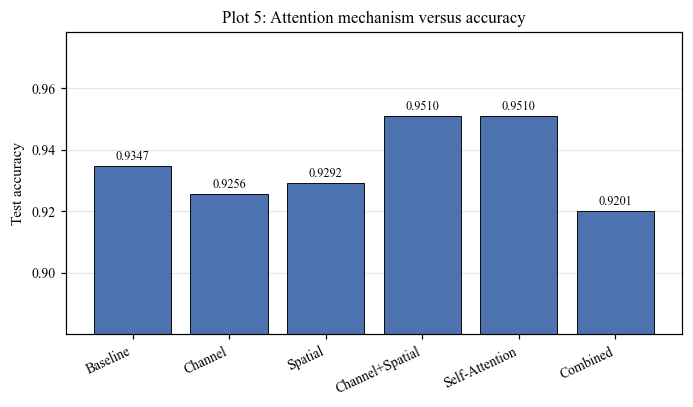

saved: plot6_type_f1.[eps|pdf|png]


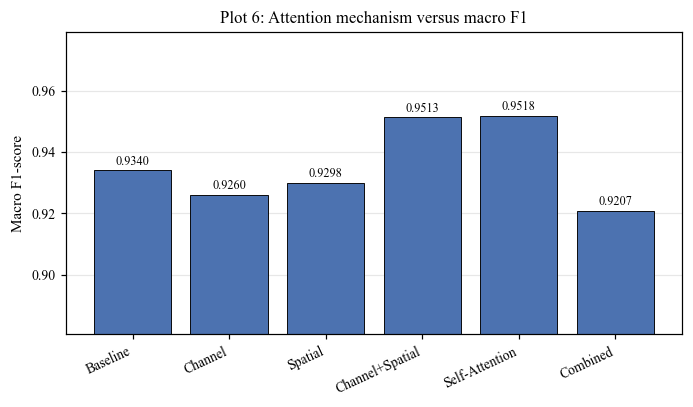

In [ ]:
# T2 CELL 5 - PLOT 5 and PLOT 6: bar graphs of test accuracy and macro F1 for each attention type.
def bar_metric(df, col, ylabel, title, fname):
    vals = df[col].values
    lo, hi = max(0, vals.min() - 0.04), min(1.0, vals.max() + 0.02)
    fig, ax = plt.subplots(figsize=(6.4, 3.8))
    bars = ax.bar(df["Model"], vals, color="#4C72B0", edgecolor="black", linewidth=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + (hi - lo) * 0.01, f"{v:.4f}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(lo, hi + (hi - lo) * 0.08)
    ax.set_ylabel(ylabel); ax.set_title(title)
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    plt.tight_layout(); save_fig(fname); plt.show()

bar_metric(df_type, "Accuracy", "Test accuracy", "Plot 5: Attention mechanism versus accuracy", "plot5_type_accuracy")
bar_metric(df_type, "Macro F1", "Macro F1-score", "Plot 6: Attention mechanism versus macro F1", "plot6_type_f1")

saved: plot7_type_acc_vs_params.[eps|pdf|png]


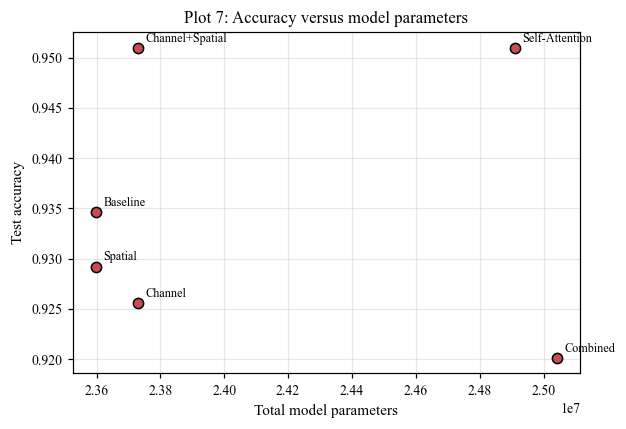

saved: plot8_type_f1_vs_time.[eps|pdf|png]


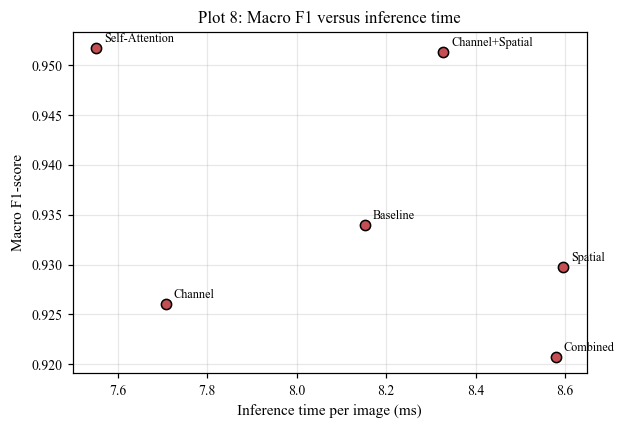

In [ ]:
# T2 CELL 6 - PLOT 7: accuracy versus total parameters.  PLOT 8: macro F1 versus inference time per image.
def scatter_tradeoff(df, xcol, ycol, xlabel, ylabel, title, fname):
    fig, ax = plt.subplots(figsize=(5.8, 4.0))
    ax.scatter(df[xcol], df[ycol], s=45, c="#C44E52", edgecolor="black", zorder=3)
    for _, r in df.iterrows():
        ax.annotate(r["Model"], (r[xcol], r[ycol]), xytext=(5, 4), textcoords="offset points", fontsize=8)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title); ax.grid(alpha=0.3)
    plt.tight_layout(); save_fig(fname); plt.show()

scatter_tradeoff(df_type, "Total params", "Accuracy", "Total model parameters", "Test accuracy",
                 "Plot 7: Accuracy versus model parameters", "plot7_type_acc_vs_params")
scatter_tradeoff(df_type, "Inference (ms/img)", "Macro F1", "Inference time per image (ms)", "Macro F1-score",
                 "Plot 8: Macro F1 versus inference time", "plot8_type_f1_vs_time")

saved: plot9_type_acc_curves.[eps|pdf|png]


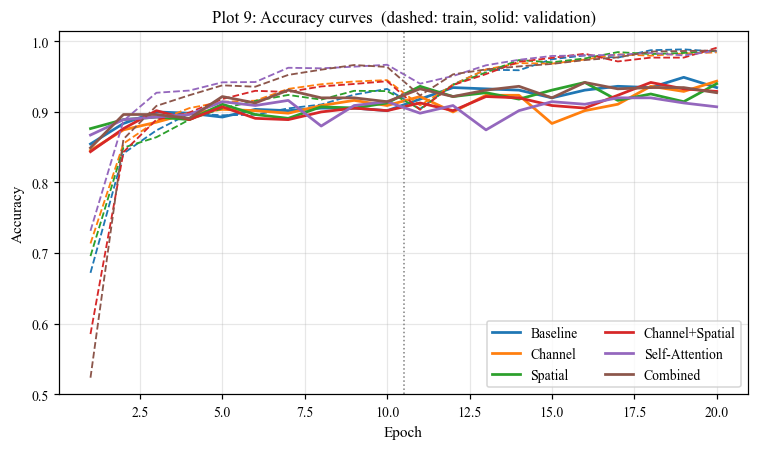

saved: plot10_type_loss_curves.[eps|pdf|png]


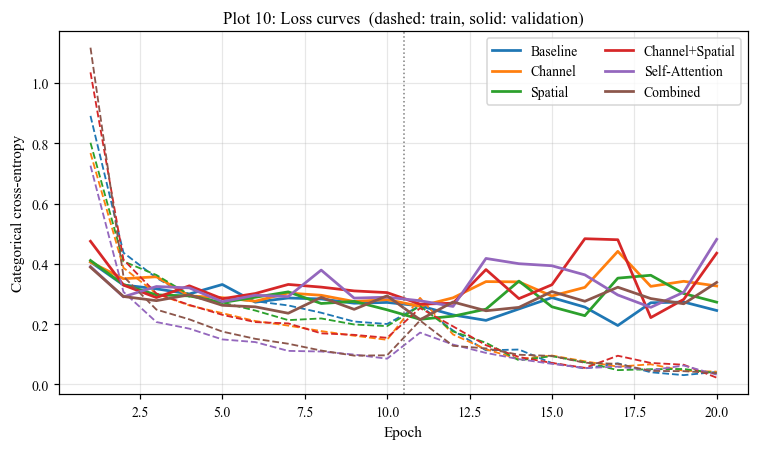

In [ ]:
# T2 CELL 7 - PLOT 9 and PLOT 10: training (dashed) and validation (solid) accuracy / loss versus epoch for the
# baseline and the attention models. The vertical line marks the start of fine-tuning.
def curves_compare(tags, key, ylabel, title, fname):
    colors = plt.cm.tab10(np.linspace(0, 1, 10))
    fig, ax = plt.subplots(figsize=(7.0, 4.2))
    for i, tag in enumerate(tags):
        h = json.load(open(f"{RUN_DIR}/{tag}_history.json"))
        ep = np.arange(1, len(h[key]) + 1)
        ax.plot(ep, h[key], "--", color=colors[i], lw=1.2)
        ax.plot(ep, h["val_" + key], "-", color=colors[i], lw=1.8, label=LABELS.get(tag, tag))
    ax.axvline(h["phase_boundary"] + 0.5, ls=":", c="gray", lw=1)
    ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel); ax.set_title(title + "  (dashed: train, solid: validation)")
    ax.legend(ncol=2); ax.grid(alpha=0.3)
    plt.tight_layout(); save_fig(fname); plt.show()

ALL_TAGS = ["A0_baseline"] + [t for t, _ in TYPE_RUNS]
curves_compare(ALL_TAGS, "accuracy", "Accuracy", "Plot 9: Accuracy curves", "plot9_type_acc_curves")
curves_compare(ALL_TAGS, "loss", "Categorical cross-entropy", "Plot 10: Loss curves", "plot10_type_loss_curves")

In [ ]:
# T3 CELL 1 - Switches for the optional runs and display labels for every new model.
RUN_P1      = True     # channel+spatial after conv2_x (56x56x256): most expensive position, set False to skip
RUN_P2P3P4  = True     # extended multi-stage run

LABELS.update({
    "B1_cs_P1": "P1 (conv2_x)", "B2_cs_P2": "P2 (conv3_x)", "A3_channel_spatial": "Channel+Spatial",
    "B4_cs_P4": "P4 (conv5_x)",
    "M1_cs_P3P4": "P3+P4", "M2_cs_P2P3P4": "P2+P3+P4",
    "O1_spatial_channel_P3": "Spatial→Channel",
    "K3_cs_k3": "k = 3", "K5_cs_k5": "k = 5",
    "X1_eca": "ECA", "X2_cbam": "CBAM", "X3_coord": "Coordinate",
})

def load_res(tag):
    return json.load(open(f"{RUN_DIR}/{tag}_results.json"))
assert os.path.exists(f"{RUN_DIR}/A3_channel_spatial_results.json"), "run the attention-type runs first"

In [ ]:
# T3 CELL 2 - The same channel->spatial module is inserted at different stages. Only the position changes.
CS = ATTENTION["channel_spatial"]
POS_RUNS = []
if RUN_P1:
    POS_RUNS.append(("B1_cs_P1", {"P1": CS}))
POS_RUNS += [("B2_cs_P2", {"P2": CS}), ("B4_cs_P4", {"P4": CS})]     # P3 = A3_channel_spatial (already trained)

for tag, att in POS_RUNS:
    results[tag] = run_one(tag, att)

[B1_cs_P1] P1: input (56, 56, 256) -> output (56, 56, 256)
Epoch 1/10
81/81 - 74s - 913ms/step - accuracy: 0.3492 - loss: 1.6378 - val_accuracy: 0.6200 - val_loss: 0.9934
Epoch 2/10
81/81 - 58s - 711ms/step - accuracy: 0.7100 - loss: 0.7600 - val_accuracy: 0.7945 - val_loss: 0.5875
Epoch 3/10
81/81 - 80s - 989ms/step - accuracy: 0.8019 - loss: 0.5432 - val_accuracy: 0.8036 - val_loss: 0.6004
Epoch 4/10
81/81 - 42s - 516ms/step - accuracy: 0.8377 - loss: 0.4607 - val_accuracy: 0.8309 - val_loss: 0.5258
Epoch 5/10
81/81 - 42s - 522ms/step - accuracy: 0.8525 - loss: 0.4018 - val_accuracy: 0.8545 - val_loss: 0.4546
Epoch 6/10
81/81 - 82s - 1s/step - accuracy: 0.8665 - loss: 0.3705 - val_accuracy: 0.8145 - val_loss: 0.5809
Epoch 7/10
81/81 - 42s - 525ms/step - accuracy: 0.8669 - loss: 0.3415 - val_accuracy: 0.8655 - val_loss: 0.4206
Epoch 8/10
81/81 - 82s - 1s/step - accuracy: 0.8957 - loss: 0.2958 - val_accuracy: 0.8382 - val_loss: 0.5066
Epoch 9/10
81/81 - 40s - 496ms/step - accuracy: 0.8

In [ ]:
# T3 CELL 3 - Attention at more than one stage: P3+P4 and (optionally) P2+P3+P4, using the same channel->spatial module.
# Each insertion gets its own layer name (a model cannot contain two layers with the same name).
def cs_at(pos):
    return lambda C: ChannelSpatialAttention(C, "cs", 7, name=f"channel_spatial_att_{pos}")

MULTI_RUNS = [("M1_cs_P3P4", {"P3": cs_at("P3"), "P4": cs_at("P4")})]
if RUN_P2P3P4:
    MULTI_RUNS.append(("M2_cs_P2P3P4", {"P2": cs_at("P2"), "P3": cs_at("P3"), "P4": cs_at("P4")}))

for tag, att in MULTI_RUNS:
    results[tag] = run_one(tag, att)

ValueError: The name "channel_spatial_att" is used 2 times in the model. All operation names should be unique.

In [ ]:
# T3 CELL 4 - Order study at P3: Spatial->Channel is trained here; Channel->Spatial is A3_channel_spatial.
results["O1_spatial_channel_P3"] = run_one("O1_spatial_channel_P3", {"P3": ATTENTION["spatial_channel"]})

In [ ]:
# T3 CELL 5 - Kernel size k in {3, 5, 7} of the spatial branch (channel->spatial at P3). k = 7 is A3_channel_spatial.
def cs_kernel(k):
    return lambda C: ChannelSpatialAttention(C, "cs", k, name=f"channel_spatial_k{k}")

for k in (3, 5):
    tag = f"K{k}_cs_k{k}"
    results[tag] = run_one(tag, {"P3": cs_kernel(k)})

In [ ]:
# T3 CELL 6 - Established mechanisms inserted at the same position (P3) with the same protocol.
# SE is the channel-attention module already trained as A1_channel (GAP -> FC -> ReLU -> FC -> sigmoid).
EXTRA_RUNS = [("X1_eca", "eca"), ("X2_cbam", "cbam"), ("X3_coord", "coord")]
for tag, kind in EXTRA_RUNS:
    results[tag] = run_one(tag, {"P3": ATTENTION[kind]})

In [ ]:
# T3 CELL 7 - Tables for each study plus the required main result table. Added params are measured against the baseline.
base = load_res("A0_baseline")

def table_from(entries):
    """entries: list of (display label, run tag, position string)."""
    rows = []
    for label, tag, pos in entries:
        r = load_res(tag)
        rows.append({"Model": label, "Position": pos,
                     "Accuracy": r["accuracy"], "Precision": r["precision"], "Recall": r["recall"], "Macro F1": r["f1"],
                     "Trainable params": r["trainable_params"], "Total params": r["total_params"],
                     "Added params": r["total_params"] - base["total_params"],
                     "Inference (ms/img)": r["inference_ms_per_image"]})
    return pd.DataFrame(rows)

FMT = {"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "Macro F1": "{:.4f}",
       "Trainable params": "{:,}", "Total params": "{:,}", "Added params": "{:,}", "Inference (ms/img)": "{:.3f}"}

def show_save(df, name, title):
    print(f"\n{title}")
    display(df.style.format(FMT))
    df.to_csv(f"{RUN_DIR}/{name}.csv", index=False)
    df.to_latex(f"{RUN_DIR}/{name}.tex", index=False, float_format="%.4f")

pos_entries = ([("P1", "B1_cs_P1", "P1")] if RUN_P1 else []) + [
    ("P2", "B2_cs_P2", "P2"), ("P3", "A3_channel_spatial", "P3"), ("P4", "B4_cs_P4", "P4")]
df_pos = table_from(pos_entries)
show_save(df_pos, "table_position", "Attention-position ablation (channel->spatial)")

multi_entries = [("P3 only", "A3_channel_spatial", "P3"), ("P4 only", "B4_cs_P4", "P4"),
                 ("P3+P4", "M1_cs_P3P4", "P3, P4")]
if RUN_P2P3P4:
    multi_entries.append(("P2+P3+P4", "M2_cs_P2P3P4", "P2, P3, P4"))
df_multi = table_from(multi_entries)
show_save(df_multi, "table_multi_position", "Single versus multiple attention positions")

df_order = table_from([("Channel→Spatial", "A3_channel_spatial", "P3"),
                       ("Spatial→Channel", "O1_spatial_channel_P3", "P3")])
show_save(df_order, "table_order", "Attention order")

df_kernel = table_from([("3 × 3", "K3_cs_k3", "P3"), ("5 × 5", "K5_cs_k5", "P3"), ("7 × 7", "A3_channel_spatial", "P3")])
df_kernel = df_kernel.rename(columns={"Model": "Spatial kernel"})
show_save(df_kernel[["Spatial kernel", "Accuracy", "Macro F1", "Inference (ms/img)", "Added params"]],
          "table_kernel", "Spatial-attention kernel size")

df_mech = table_from([("No attention", "A0_baseline", "–"), ("Channel / SE", "A1_channel", "P3"),
                      ("Spatial", "A2_spatial", "P3"), ("ECA", "X1_eca", "P3"), ("CBAM", "X2_cbam", "P3"),
                      ("Self-attention", "A4_self_attention", "P3"), ("Coordinate", "X3_coord", "P3")])
show_save(df_mech, "table_mechanisms", "Comparison of attention mechanisms at P3")

df_main = table_from([("Baseline", "A0_baseline", "–"), ("Channel attention", "A1_channel", "P3"),
                      ("Spatial attention", "A2_spatial", "P3"), ("Channel+Spatial", "B2_cs_P2", "P2"),
                      ("Channel+Spatial", "A3_channel_spatial", "P3"), ("Channel+Spatial", "B4_cs_P4", "P4"),
                      ("Self-attention", "A4_self_attention", "P3"), ("ECA", "X1_eca", "P3"), ("CBAM", "X2_cbam", "P3")])
show_save(df_main[["Model", "Position", "Accuracy", "Precision", "Recall", "Macro F1", "Total params", "Inference (ms/img)"]],
          "table_main_results", "Main result table")

In [ ]:
# T3 CELL 8 - PLOT 11 / 12: accuracy and macro F1 versus attention position.  PLOT 13: single versus multiple positions.
bar_metric(df_pos, "Accuracy", "Test accuracy", "Plot 11: Attention position versus accuracy", "plot11_position_accuracy")
bar_metric(df_pos, "Macro F1", "Macro F1-score", "Plot 12: Attention position versus macro F1", "plot12_position_f1")

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.8))
for ax, col, yl in zip(axes, ["Accuracy", "Macro F1"], ["Test accuracy", "Macro F1-score"]):
    vals = df_multi[col].values
    lo = max(0, vals.min() - 0.04); hi = min(1.0, vals.max() + 0.02)
    bars = ax.bar(df_multi["Model"], vals, color="#55A868", edgecolor="black", linewidth=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + (hi - lo) * 0.01, f"{v:.4f}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(lo, hi + (hi - lo) * 0.08); ax.set_ylabel(yl); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.suptitle("Plot 13: Attention at one versus several stages")
plt.tight_layout(); save_fig("plot13_multi_position"); plt.show()

In [ ]:
# T3 CELL 9 - PLOT 14: attention order.  PLOT 15: kernel size (accuracy, macro F1, inference time).
# PLOT 16 / 17: accuracy and macro F1 for all attention mechanisms.
bar_metric(df_order, "Accuracy", "Test accuracy", "Plot 14: Channel→Spatial versus Spatial→Channel", "plot14_order_accuracy")

fig, ax1 = plt.subplots(figsize=(5.6, 3.8))
x = np.arange(len(df_kernel)); w = 0.35
ax1.bar(x - w / 2, df_kernel["Accuracy"], w, label="Accuracy", color="#4C72B0", edgecolor="black", linewidth=0.6)
ax1.bar(x + w / 2, df_kernel["Macro F1"], w, label="Macro F1", color="#DD8452", edgecolor="black", linewidth=0.6)
lo = min(df_kernel["Accuracy"].min(), df_kernel["Macro F1"].min()) - 0.03
ax1.set_ylim(max(0, lo), 1.0); ax1.set_xticks(x); ax1.set_xticklabels(df_kernel["Spatial kernel"])
ax1.set_xlabel("Spatial kernel size"); ax1.set_ylabel("Score")
ax2 = ax1.twinx()
ax2.plot(x, df_kernel["Inference (ms/img)"], "k-o", label="Inference time"); ax2.set_ylabel("Inference time (ms/img)")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower right"); ax1.set_title("Plot 15: Spatial kernel size")
plt.tight_layout(); save_fig("plot15_kernel_size"); plt.show()

bar_metric(df_mech, "Accuracy", "Test accuracy", "Plot 16: Attention mechanism versus accuracy", "plot16_mech_accuracy")
bar_metric(df_mech, "Macro F1", "Macro F1-score", "Plot 17: Attention mechanism versus macro F1", "plot17_mech_f1")

In [ ]:
# T3 CELL 11 - PLOT 20 / 21: validation accuracy and loss curves for the position study and for the mechanism study.
POS_TAGS  = ["A0_baseline"] + [t for _, t, _ in pos_entries]
MECH_TAGS = ["A0_baseline", "A1_channel", "X1_eca", "X2_cbam", "A4_self_attention", "X3_coord"]
LABELS.update({"A0_baseline": "Baseline", "A1_channel": "Channel / SE", "A4_self_attention": "Self-attention"})

curves_compare(POS_TAGS,  "accuracy", "Accuracy", "Plot 20: Accuracy curves by attention position", "plot20_position_acc_curves")
curves_compare(MECH_TAGS, "loss", "Categorical cross-entropy", "Plot 21: Loss curves by attention mechanism", "plot21_mech_loss_curves")